In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.tsa.api import VAR

# Load the data
file_path = 'data_csv/var_data.csv'
df = pd.read_csv(file_path, index_col='Unnamed: 0')
df.index = pd.to_datetime(df.index) # Ensure index is datetime
df.index.name = 'Date'



df.rename(columns={"new york":"newyork", 'las vegas':'lasvegas'},inplace=True)
print(df.head())

cs_cols = ['cs','cs10','charlotte','cleveland','denver','lasvegas','newyork']

for col in cs_cols:
    if col in df.columns:
        df[f'log_{col}'] = np.log(df[col])
    else:
        print(f"Warning: Column '{col}' not found in dataframe.")

# Check the transformed data
cols_to_check = ['unemp', 'pce_rate', 'ffr'] + [f'log_{col}' for col in cs_cols if col in df.columns]
print(df[cols_to_check].head())

print



                cs       cs10   ffr  unemp  pce_rate  charlotte  cleveland  \
Date                                                                         
1987-01-01  63.732  63.103814  6.43    6.6      3.16  63.559024  54.057393   
1987-02-01  64.131  63.804972  6.10    6.6      3.22  64.028844  54.229218   
1987-03-01  64.467  64.425674  6.13    6.6      3.41  64.105242  54.365756   
1987-04-01  64.972  65.063393  6.37    6.3      3.57  64.892990  54.155370   
1987-05-01  65.546  65.815103  6.85    6.3      3.66  65.222790  54.726192   

               denver   lasvegas    newyork  
Date                                         
1987-01-01  50.348017  66.418966  74.678440  
1987-02-01  50.160468  67.574198  76.043687  
1987-03-01  50.383478  67.850132  77.237075  
1987-04-01  50.744628  68.186064  78.281527  
1987-05-01  50.763538  67.927091  79.675331  
            unemp  pce_rate   ffr    log_cs  log_cs10  log_charlotte  \
Date                                                       

C:\Users\tuoma\AppData\Local\Temp\ipykernel_27488\945397110.py:15: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={"new york":"newyork", 'las vegas':'lasvegas'},inplace=True)


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [6]:



def _compute_stata_oirf(results, steps):
    """
    Computes orthogonalized IRFs matching Stata's default `var` ML covariance
    estimator (dividing Sigma_u by T instead of T - Kp - 1).
    """
    df_scale = np.sqrt(results.df_resid / results.nobs)
    return results.irf(steps).orth_irfs * df_scale


def _bootstrap_stata_oirf_se(results, steps=60, n_boot=500, seed=55555):
    """
    Implements Stata's exact residual bootstrap algorithm (`irf create, bs reps(R)`)
    as documented in [TS] irf create (Methods and formulas, p. 26):
      1. Condition on the first p observations (Y_init).
      2. Resample T residual vectors (1 x K) with replacement.
      3. Recursively simulate synthetic sample Y* of length p + T.
      4. Re-estimate VAR(p), compute OIRFs (with 1/T ML scaling), and return
         the sample standard deviation (ddof=1) across R replications.
    """
    rng = np.random.default_rng(seed)

    p = results.k_ar
    T, K = results.resid.shape
    endog = results.model.endog              # Shape: (p + T, K)
    y_init = endog[:p].copy()                # First p presample observations: (p, K)
    resid_values = results.resid.values      # Estimated residuals: (T, K)

    intercept = results.intercept            # Shape: (K,)
    coefs = results.coefs                    # Shape: (p, K, K) -> A_1, ..., A_p

    boot_oirfs = np.empty((n_boot, steps + 1, K, K))

    for r in range(n_boot):
        # Step 3a: Draw T row vectors with replacement from residuals
        sampled_idx = rng.integers(0, T, size=T)
        u_star = resid_values[sampled_idx]

        # Step 3b: Construct synthetic sample starting from the p initial observations
        y_star = np.empty((p + T, K))
        y_star[:p] = y_init

        for t in range(p, p + T):
            # y_t* = v + A_1 y_{t-1}* + ... + A_p y_{t-p}* + u_t*
            lags_reversed = y_star[t - p:t][::-1]  # [y_{t-1}*, ..., y_{t-p}*]
            y_star[t] = intercept + np.einsum('pij,pj->i', coefs, lags_reversed) + u_star[t - p]

        # Step 3c & 3d: Fit VAR(p) on synthetic sample and store OIRFs
        boot_res = VAR(y_star).fit(p)
        boot_oirfs[r] = _compute_stata_oirf(boot_res, steps)

    # Step 4: Standard error is the sample standard deviation across R replications
    return np.std(boot_oirfs, axis=0, ddof=1)


def run_var_analysis(
    df,
    cs_cols,
    start_date=None,
    end_date=None,
    lags=12,
    irf_steps=60,
    n_boot=500,
    seed=55555
):
    """
    Fits 4-variable SVAR models for each Case-Shiller index and computes
    orthogonalized IRFs with symmetric bootstrapped 95% confidence intervals
    matching Stata's `irf create, step(60) bs reps(500)`.
    """
    irf_results = {}
    z_crit = norm.ppf(0.975)  # ~1.959964 (matches Stata's 95% normal CI)

    data = df.copy()
    if start_date is not None:
        data = data.loc[data.index >= start_date]
    if end_date is not None:
        data = data.loc[data.index <= end_date]

    print(f"Sample Window (including {lags} lags): "
          f"{data.index.min().date()} to {data.index.max().date()}")
    print(f"{'Model':<12} | {'Eff. Obs (T)':<12} | {'FFR Residual SD':<16} | {'FFR Cholesky Shock':<18}")
    print("-" * 66)

    for cs_col in cs_cols:
        # Cholesky ordering: unemp, pce_rate, ffr, log(cs_col)
        current_vars = ['unemp', 'pce_rate', 'ffr', f'log_{cs_col}']
        data_subset = data[current_vars].dropna()

        if data_subset.empty:
            print(f"Warning: No data for {cs_col} in the specified range.")
            continue

        results = VAR(data_subset).fit(lags)
        ffr_idx = 2  # 'ffr'
        cs_idx = 3   # f'log_{cs_col}'

        # Stata ML scaling factor: sqrt((T - Kp - 1) / T)
        df_scale = np.sqrt(results.df_resid / results.nobs)
        ffr_resid_std = results.resid['ffr'].std(ddof=1)
        P_stata = np.linalg.cholesky(results.sigma_u) * df_scale
        ffr_shock_size = P_stata[ffr_idx, ffr_idx]

        print(f"{cs_col:<12} | {results.nobs:<12} | {ffr_resid_std:<16.7f} | {ffr_shock_size:<18.8f}")

        # Point estimates (OIRF) and bootstrapped standard errors (stdoirf)
        oirf_matrix = _compute_stata_oirf(results, irf_steps)
        stdoirf_matrix = _bootstrap_stata_oirf_se(
            results, steps=irf_steps, n_boot=n_boot, seed=seed
        )

        response = oirf_matrix[:, cs_idx, ffr_idx]
        stderr = stdoirf_matrix[:, cs_idx, ffr_idx]

        # Symmetric 95% confidence intervals
        lower = response - z_crit * stderr
        upper = response + z_crit * stderr

        irf_results[cs_col] = (response, lower, upper)

    return irf_results


def plot_irf_grid(irf_results, cs_names, ylim=(-0.042, 0.006)):
    """
    Plots the 7 IRF results in a 4x2 grid matching Figure 22 in the thesis.
    """
    if not irf_results:
        print("No results to plot.")
        return

    plt.style.use('seaborn-v0_8-whitegrid')
    n_rows, n_cols = 4, 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 12), sharex=True, sharey=True)
    axes_flat = axes.flatten()

    for i, (cs_col, (response, lower, upper)) in enumerate(irf_results.items()):
        ax = axes_flat[i]
        steps = np.arange(len(response))

        # Mean OIRF and symmetric 95% bootstrapped confidence band
        ax.plot(steps, response, color='#1f77b4', linewidth=1.8)
        ax.fill_between(steps, lower, upper, color='#1f77b4', alpha=0.22, edgecolor='none')
        ax.axhline(0, color='black', linestyle='--', linewidth=0.8)

        title_name = cs_names.get(cs_col, cs_col)
        ax.set_title(title_name, fontsize=13, fontweight='bold', pad=8)
        ax.set_ylim(ylim)
        ax.set_yticks([0.00, -0.01, -0.02, -0.03, -0.04])
        ax.set_xticks([0, 20, 40, 60])

        # Label left column Y-axes matching Figure 22
        if i % n_cols == 0:
            ax.set_ylabel('Response', fontsize=11)

    # Set X-axis label and ticks on the bottom panel(s)
    axes_flat[len(irf_results) - 1].set_xlabel('Months', fontsize=11)
    axes_flat[len(irf_results) - 1].tick_params(labelbottom=True)

    # Remove unused bottom-right subplot
    for j in range(len(irf_results), len(axes_flat)):
        fig.delaxes(axes_flat[j])

    fig.suptitle(
        'Orthogonalized IRF: Response of House Prices to FFR Shock\n(95 % Bootstrapped CI)',
        fontsize=15,
        fontweight='bold',
        y=0.98
    )

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

In [7]:



def _compute_stata_oirf(results, steps):
    """
    Computes orthogonalized IRFs matching Stata's default `var` ML covariance
    estimator (dividing Sigma_u by T instead of T - Kp - 1).
    """
    df_scale = np.sqrt(results.df_resid / results.nobs)
    return results.irf(steps).orth_irfs * df_scale


def _bootstrap_stata_oirf_se(results, steps=60, n_boot=500, seed=55555):
    """
    Implements Stata's exact residual bootstrap algorithm (`irf create, bs reps(R)`)
    as documented in [TS] irf create (Methods and formulas, p. 26):
      1. Condition on the first p observations (Y_init).
      2. Resample T residual vectors (1 x K) with replacement.
      3. Recursively simulate synthetic sample Y* of length p + T.
      4. Re-estimate VAR(p), compute OIRFs (with 1/T ML scaling), and return
         the sample standard deviation (ddof=1) across R replications.
    """
    rng = np.random.default_rng(seed)

    p = results.k_ar
    T, K = results.resid.shape
    endog = results.model.endog              # Shape: (p + T, K)
    y_init = endog[:p].copy()                # First p presample observations: (p, K)
    resid_values = results.resid.values      # Estimated residuals: (T, K)

    intercept = results.intercept            # Shape: (K,)
    coefs = results.coefs                    # Shape: (p, K, K) -> A_1, ..., A_p

    boot_oirfs = np.empty((n_boot, steps + 1, K, K))

    for r in range(n_boot):
        # Step 3a: Draw T row vectors with replacement from residuals
        sampled_idx = rng.integers(0, T, size=T)
        u_star = resid_values[sampled_idx]

        # Step 3b: Construct synthetic sample starting from the p initial observations
        y_star = np.empty((p + T, K))
        y_star[:p] = y_init

        for t in range(p, p + T):
            # y_t* = v + A_1 y_{t-1}* + ... + A_p y_{t-p}* + u_t*
            lags_reversed = y_star[t - p:t][::-1]  # [y_{t-1}*, ..., y_{t-p}*]
            y_star[t] = intercept + np.einsum('pij,pj->i', coefs, lags_reversed) + u_star[t - p]

        # Step 3c & 3d: Fit VAR(p) on synthetic sample and store OIRFs
        boot_res = VAR(y_star).fit(p)
        boot_oirfs[r] = _compute_stata_oirf(boot_res, steps)

    # Step 4: Standard error is the sample standard deviation across R replications
    return np.std(boot_oirfs, axis=0, ddof=1)


def run_var_analysis(
    df,
    cs_cols,
    start_date=None,
    end_date=None,
    lags=12,
    irf_steps=60,
    n_boot=500,
    seed=55555
):
    """
    Fits 4-variable SVAR models for each Case-Shiller index and computes
    orthogonalized IRFs with symmetric bootstrapped 95% confidence intervals
    matching Stata's `irf create, step(60) bs reps(500)`.
    """
    irf_results = {}
    z_crit = norm.ppf(0.975)  # ~1.959964 (matches Stata's 95% normal CI)

    data = df.copy()
    if start_date is not None:
        data = data.loc[data.index >= start_date]
    if end_date is not None:
        data = data.loc[data.index <= end_date]

    print(f"Sample Window (including {lags} lags): "
          f"{data.index.min().date()} to {data.index.max().date()}")
    print(f"{'Model':<12} | {'Eff. Obs (T)':<12} | {'FFR Residual SD':<16} | {'FFR Cholesky Shock':<18}")
    print("-" * 66)

    for cs_col in cs_cols:
        # Cholesky ordering: unemp, pce_rate, ffr, log(cs_col)
        current_vars = ['unemp', 'pce_rate', 'ffr', f'log_{cs_col}']
        data_subset = data[current_vars].dropna()

        if data_subset.empty:
            print(f"Warning: No data for {cs_col} in the specified range.")
            continue

        results = VAR(data_subset).fit(lags)
        ffr_idx = 2  # 'ffr'
        cs_idx = 3   # f'log_{cs_col}'

        # Stata ML scaling factor: sqrt((T - Kp - 1) / T)
        df_scale = np.sqrt(results.df_resid / results.nobs)
        ffr_resid_std = results.resid['ffr'].std(ddof=1)
        P_stata = np.linalg.cholesky(results.sigma_u) * df_scale
        ffr_shock_size = P_stata[ffr_idx, ffr_idx]

        print(f"{cs_col:<12} | {results.nobs:<12} | {ffr_resid_std:<16.7f} | {ffr_shock_size:<18.8f}")

        # Point estimates (OIRF) and bootstrapped standard errors (stdoirf)
        oirf_matrix = _compute_stata_oirf(results, irf_steps)
        stdoirf_matrix = _bootstrap_stata_oirf_se(
            results, steps=irf_steps, n_boot=n_boot, seed=seed
        )

        response = oirf_matrix[:, cs_idx, ffr_idx]
        stderr = stdoirf_matrix[:, cs_idx, ffr_idx]

        # Symmetric 95% confidence intervals
        lower = response - z_crit * stderr
        upper = response + z_crit * stderr

        irf_results[cs_col] = (response, lower, upper)

    return irf_results


def plot_irf_grid(irf_results, cs_names, ylim=(-0.042, 0.006)):
    """
    Plots the 7 IRF results in a 4x2 grid matching Figure 22 in the thesis.
    """
    if not irf_results:
        print("No results to plot.")
        return

    plt.style.use('seaborn-v0_8-whitegrid')
    n_rows, n_cols = 4, 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 12), sharex=True, sharey=True)
    axes_flat = axes.flatten()

    for i, (cs_col, (response, lower, upper)) in enumerate(irf_results.items()):
        ax = axes_flat[i]
        steps = np.arange(len(response))

        # Mean OIRF and symmetric 95% bootstrapped confidence band
        ax.plot(steps, response, color='#1f77b4', linewidth=1.8)
        ax.fill_between(steps, lower, upper, color='#1f77b4', alpha=0.22, edgecolor='none')
        ax.axhline(0, color='black', linestyle='--', linewidth=0.8)

        title_name = cs_names.get(cs_col, cs_col)
        ax.set_title(title_name, fontsize=13, fontweight='bold', pad=8)
        ax.set_ylim(ylim)
        ax.set_yticks([0.00, -0.01, -0.02, -0.03, -0.04])
        ax.set_xticks([0, 20, 40, 60])

        # Label left column Y-axes matching Figure 22
        if i % n_cols == 0:
            ax.set_ylabel('Response', fontsize=11)

    # Set X-axis label and ticks on the bottom panel(s)
    axes_flat[len(irf_results) - 1].set_xlabel('Months', fontsize=11)
    axes_flat[len(irf_results) - 1].tick_params(labelbottom=True)

    # Remove unused bottom-right subplot
    for j in range(len(irf_results), len(axes_flat)):
        fig.delaxes(axes_flat[j])

    fig.suptitle(
        'Orthogonalized IRF: Response of House Prices to FFR Shock\n(95 % Bootstrapped CI)',
        fontsize=15,
        fontweight='bold',
        y=0.98
    )

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

c:\Users\tuoma\anaconda3\envs\thesis-data\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Sample Window (including 12 lags): 1987-01-01 to 2007-07-01
Model        | Eff. Obs (T) | FFR Residual SD  | FFR Cholesky Shock
------------------------------------------------------------------
cs           | 235          | 0.1247703        | 0.12176053        


c:\Users\tuoma\anaconda3\envs\thesis-data\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


cs10         | 235          | 0.1268970        | 0.12438087        


c:\Users\tuoma\anaconda3\envs\thesis-data\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


newyork      | 235          | 0.1261822        | 0.12374911        


... (4 outputs left out)

c:\Users\tuoma\anaconda3\envs\thesis-data\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


charlotte    | 235          | 0.1243224        | 0.12239021        


c:\Users\tuoma\anaconda3\envs\thesis-data\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


cleveland    | 235          | 0.1250870        | 0.12294897        


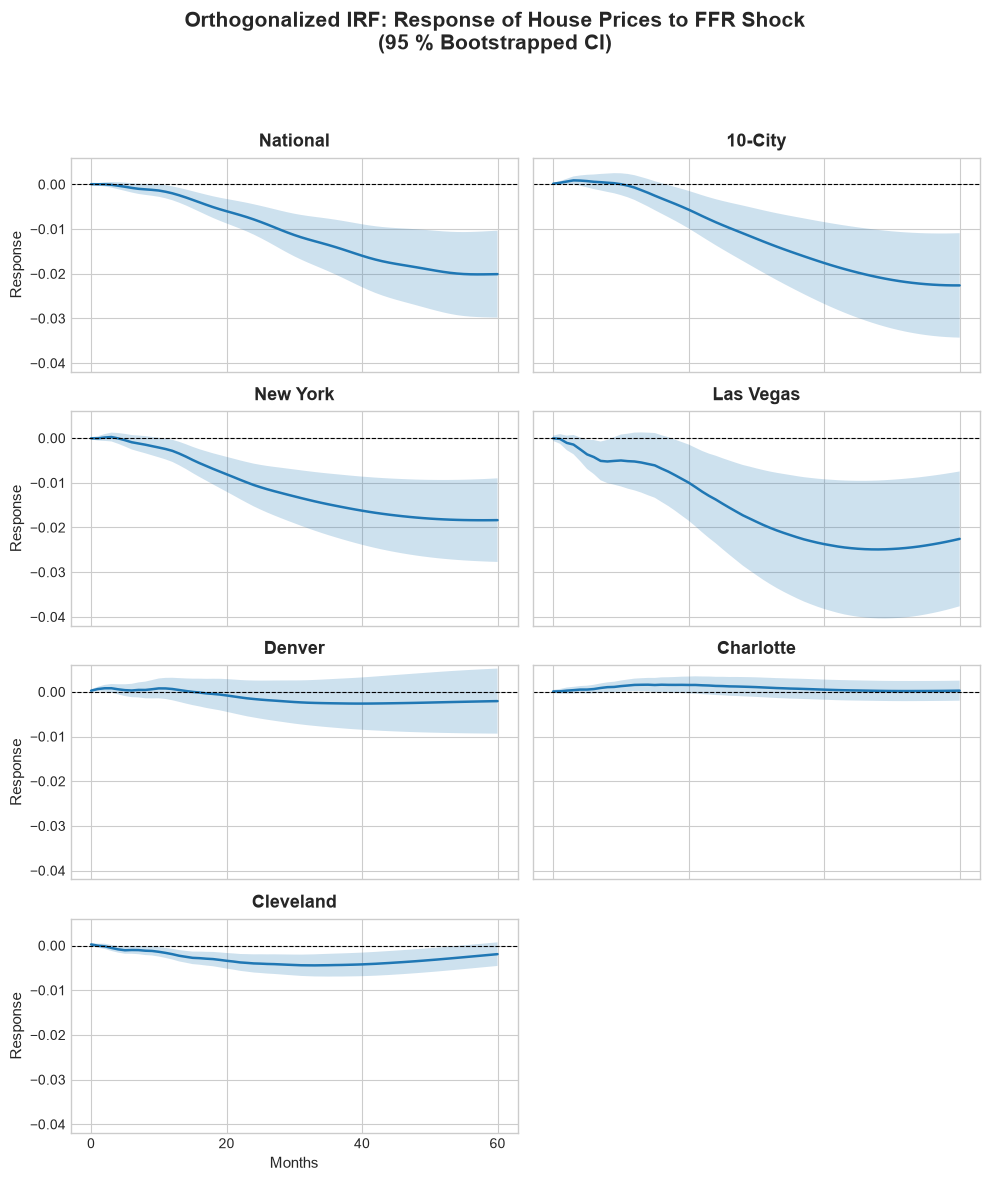

In [8]:
cs_cols = ['cs', 'cs10', 'newyork', 'lasvegas', 'denver', 'charlotte', 'cleveland']

cs_names = {
    'cs': 'National',
    'cs10': '10-City',
    'newyork': 'New York',
    'lasvegas': 'Las Vegas',
    'denver': 'Denver',
    'charlotte': 'Charlotte',
    'cleveland': 'Cleveland'
}

irf_results = run_var_analysis(
    df,
    cs_cols=cs_cols,
    start_date='1987-01-01',
    end_date='2007-07-01',
    lags=12,
    irf_steps=60,
    n_boot=500,
    seed=55555
)

plot_irf_grid(irf_results, cs_names)